First 5 Records:


,Date,PM2.5,PM10,CO,AQI
0,2025-01-01,70.484907,67.928256,0.841776,117.5
1,2025-01-02,46.280286,101.627874,1.262746,95.9
2,2025-01-03,78.508122,114.068827,1.276999,141.8
3,2025-01-04,81.930165,124.655558,1.675716,153.2
4,2025-01-05,29.881367,127.780664,1.492289,81.2


Dataset Shape: (60, 5)

Missing Values:


Date     0
PM2.5    0
PM10     0
CO       0
AQI      0
dtype: int64


Summary Statistics:


,Date,PM2.5,PM10,CO,AQI
count,60,60.000000,60.000000,60.000000,60.000000
mean,2025-01-30 12:00:00,66.175138,105.347769,1.182678,122.491667
min,2025-01-01 00:00:00,29.881367,66.816989,0.453784,81.200000
25%,2025-01-15 18:00:00,56.344877,94.722651,0.905380,105.325000
50%,2025-01-30 12:00:00,67.200736,104.440085,1.154600,123.500000
75%,2025-02-14 06:00:00,76.450059,121.227305,1.347814,135.300000
max,2025-03-01 00:00:00,103.549657,150.044472,2.219852,176.300000
std,NaN,14.141657,19.254347,0.356892,19.695515


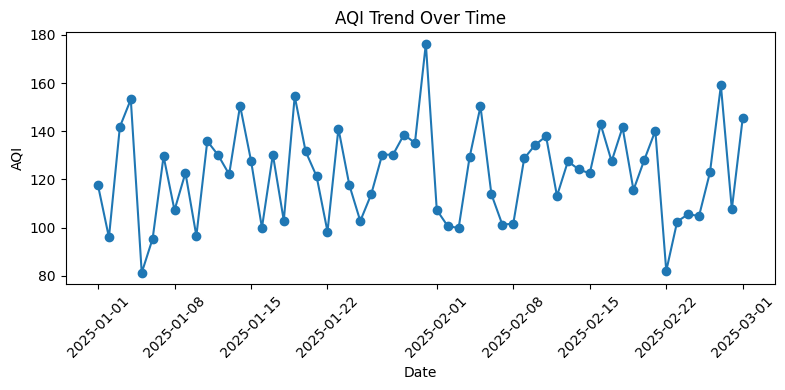

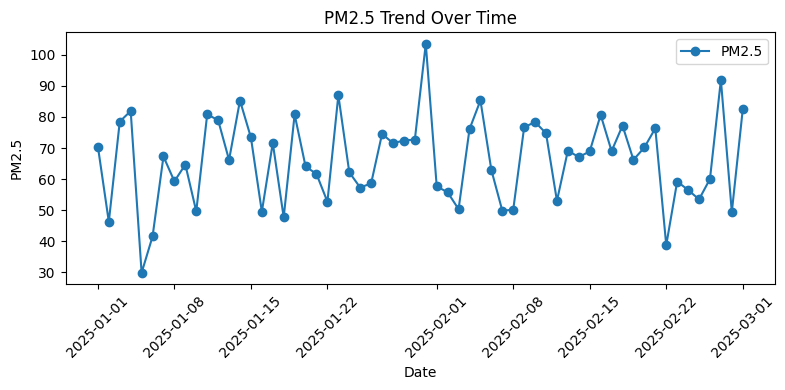

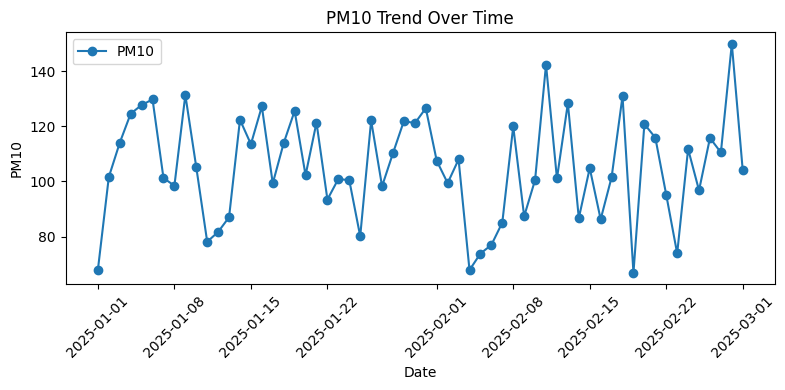

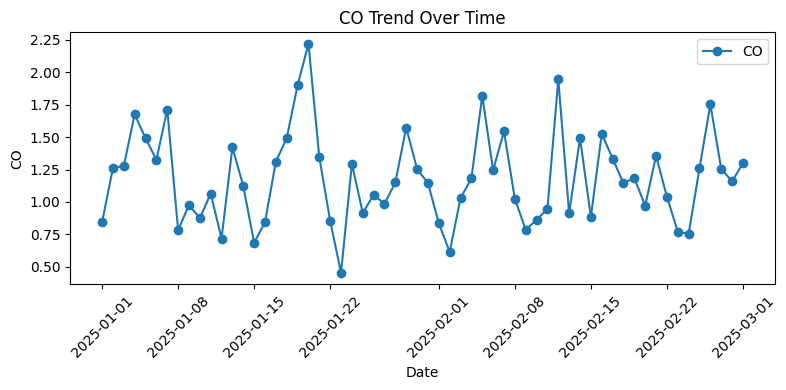

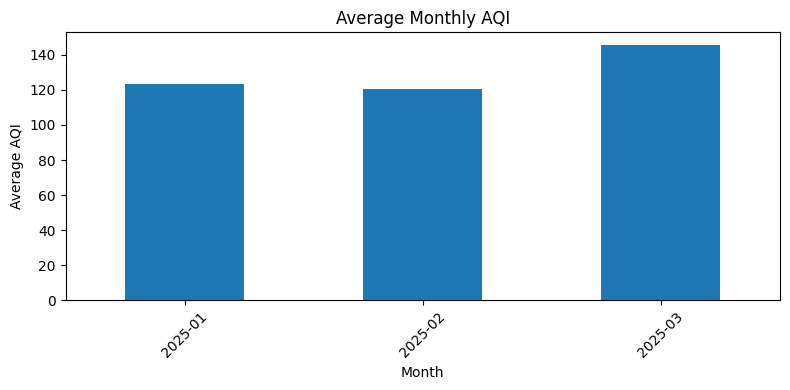

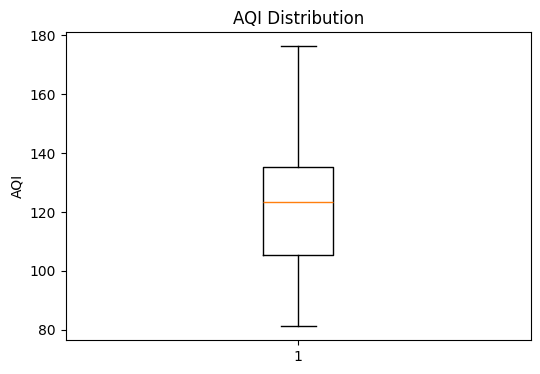

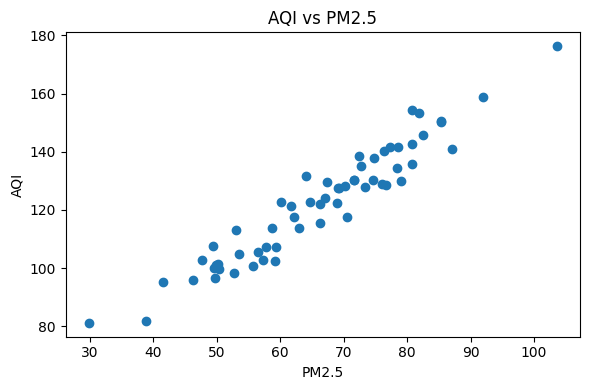

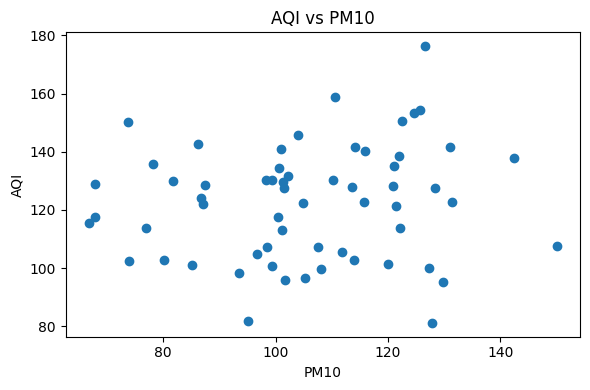

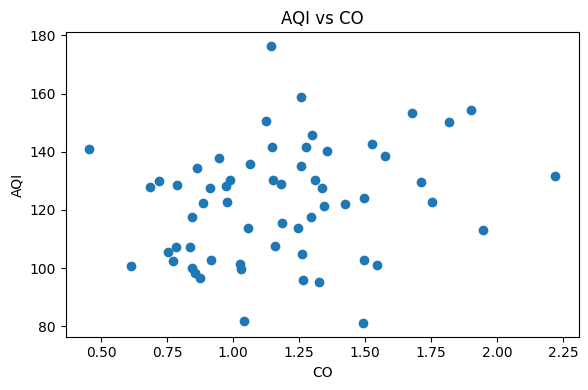

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load and explore the dataset
df = pd.read_csv("City_Air_Quality.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")

print("First 5 Records:")
display(df.head())

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
display(df.isnull().sum())

print("\nSummary Statistics:")
display(df.describe())

# 2. AQI trend over time
plt.figure(figsize=(8, 4))
plt.plot(df["Date"], df["AQI"], marker="o")
plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Pollutant levels over time
for col in ["PM2.5", "PM10", "CO"]:
    plt.figure(figsize=(8, 4))
    plt.plot(df["Date"], df[col], marker="o", label=col)
    plt.title(col + " Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# 4. Average monthly AQI
df["Month"] = df["Date"].dt.to_period("M").astype(str)
monthly_aqi = df.groupby("Month")["AQI"].mean()

monthly_aqi.plot(kind="bar", figsize=(8, 4), title="Average Monthly AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. AQI distribution using a box plot
plt.figure(figsize=(6, 4))
plt.boxplot(df["AQI"].dropna())
plt.title("AQI Distribution")
plt.ylabel("AQI")
plt.show()

# 6. Relationship between AQI and pollutants
for col in ["PM2.5", "PM10", "CO"]:
    plt.figure(figsize=(6, 4))
    plt.scatter(df[col], df["AQI"])
    plt.title("AQI vs " + col)
    plt.xlabel(col)
    plt.ylabel("AQI")
    plt.tight_layout()
    plt.show()